# U.S.-China "30-for-30" List — What Exclusion From the Labor 301 Would Do to China's Rate

On **September 27, 2026** the White House released the working procedures of a
U.S.-China **Board of Trade** and the terms of reference of its **"30-for-30"
framework**: two comparably valued lists of goods, roughly $30B each at
calendar-2024 trade values, approved "with a view toward providing reduced tariff
treatment to those goods in a reciprocal manner." The U.S. import list names
**77 HTS8 codes** of Chinese consumer goods (toys, plastic tableware, small
appliances, home textiles, juvenile furniture, sporting goods, Christmas articles).

**This is a framework, not a tariff action.** Future reductions "will be determined
and implemented in accordance with each side's domestic legal processes" — there is
no rate, date, authority or chapter 99 heading yet, so nothing is in the published
series. The main notebook carries the list as a **staged-off** Phase-3 regime
(`CHINA_30FOR30_LIVE = False`).

**The question here:** every listed code currently carries exactly one modeled duty
for China — the **12.5% forced-labor Section 301** of Jul 24, 2026. If the promised
"reduced tariff treatment" arrives as an exclusion from that duty, the list returns
to its **2024 tariff level**. How much does China's import-weighted rate move, where
does the change come from, and what tariff does the list still carry afterwards?

**Generates:** `figures/china-30for30-*.png`

**Run after** `make-tariff-by-country-by-time.ipynb` — reads
[country-by-time.csv](country-by-time.csv) and imports the tariff engine from that
notebook, then activates the staged regime by hand for the hypothetical.

In [1]:
%matplotlib inline
import json
import io
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
figfile = "./figures/"
os.makedirs(figfile, exist_ok=True)

plt.rcParams.update({
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.linewidth':    2,
    'axes.labelweight':  'bold',
    'axes.titleweight':  'bold',
    'axes.titlesize':    18,
    'axes.labelsize':    16,
    'xtick.labelsize':   12,
    'ytick.labelsize':   12,
    'legend.frameon':    False,
    'legend.fontsize':   12,
    'grid.alpha':        0.3,
    'grid.linestyle':    '--',
    'savefig.bbox':      'tight',
})

PALETTE = {
    'aggregate':  'black',
    'primary':    'darkblue',
    'secondary':  '#8B0000',   # rises / duties added
    'tertiary':   'darkgreen', # falls / duties removed
    'neutral':    'dimgray',
}

CHINA = "5700"
# Import-weight year — keep in sync with WEIGHT_YEAR in the main notebook.
WEIGHT_YEAR = 2024
# The hypothetical is evaluated against the current policy state. No action after
# Aug 22, 2026 touches China, so any date from then on gives the same answer.
EVAL_DATE = pd.Timestamp("2026-09-28")

## Load the tariff engine

Execute the main notebook's code cells in order and stop once `tariff_imports` is
defined — data loaders, product lists, masks, apply functions and the registry, but
not the panel loop. The staged 30-for-30 regime is defined there but not registered.

In [3]:
_nb = json.load(io.open('make-tariff-by-country-by-time.ipynb', encoding='utf-8'))

for _cell in _nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break

assert not CHINA_30FOR30_LIVE, "staged regime must be OFF in the main notebook"
assert "China-30for30" not in [r["name"] for r in STACKED_REGIMES]
print(f"engine loaded — {len(TARIFF_ACTIONS)} tariff actions, "
      f"{len(STACKED_REGIMES)} stacked regimes; 30-for-30 regime staged off "
      f"(placeholder date {CHINA_30FOR30_EFFECTIVE_DATE}, rate {CHINA_30FOR30_RATE})")

engine loaded — 89 tariff actions, 57 stacked regimes; 30-for-30 regime staged off (placeholder date 2026-12-01, rate -12.5)


## Section 1 — What the list covers

The engine form of the list (`china-30for30-model-list.csv`) has 70 HS8 codes plus
13 HTS10 lines that resolve the seven juvenile-furniture "Ex-Out" rows to exactly
the products their descriptions name. The 2024 collected rate is customs duty over
import value in the Census data — the MFN rate plus whatever legacy 2018-19 Section
301 duty each line carried — which is the level the list would return to.

In [4]:
china = load_imports(CHINA, year=WEIGHT_YEAR)
lst = STACKED_INCLUDE_LISTS["China-30for30"]
in_list = china["HS8"].isin(lst["hs8"]) | china["HS10"].isin(lst["hs10"])
n_codes = len(china_30for30_list["list_hts8"].unique())

def product_group(hs8):
    if hs8.startswith("9503"):            return "Toys"
    if hs8[:4] in ("9504", "9505", "9506", "9507"):
                                          return "Games, Christmas & sporting goods"
    if hs8[:2] in ("84", "85"):           return "Small appliances & lamps"
    if hs8[:2] == "63" or hs8[:4] == "9404":
                                          return "Home textiles & bedding"
    if hs8[:2] == "39":                   return "Plastic tableware & beads"
    if hs8[:4] in ("9401", "9403"):       return "Juvenile furniture & car seats"
    return "Other (fireworks, umbrellas, artificial flowers, brushes, flasks)"

china["group"] = china["HS8"].map(product_group)
cov = (china[in_list].groupby("group")
       .agg(codes=("HS8", "nunique"), imports=("imports", "sum"), duty=("duty", "sum"),
            share=("share", "sum"))
       .sort_values("imports", ascending=False))
cov["imports ($B)"] = cov["imports"] / 1e9
cov["share of list (%)"] = 100 * cov["imports"] / cov["imports"].sum()
cov["share of China imports (%)"] = 100 * cov["share"]
cov["2024 collected rate (%)"] = 100 * cov["duty"] / cov["imports"]
total = pd.Series({"codes": n_codes, "imports ($B)": cov["imports"].sum() / 1e9,
                   "share of list (%)": 100.0, "share of China imports (%)": 100 * cov["share"].sum(),
                   "2024 collected rate (%)": 100 * cov["duty"].sum() / cov["imports"].sum()},
                  name="TOTAL")
cov_table = pd.concat([cov[total.index], total.to_frame().T]).round(2)
cov_table

,codes,imports ($B),share of list (%),share of China imports (%),2024 collected rate (%)
Toys,1.0,13.45,45.41,3.13,0.00
Small appliances & lamps,15.0,7.47,25.21,1.74,4.10
Plastic tableware & beads,3.0,3.48,11.74,0.81,4.58
"Other (fireworks, umbrellas, artificial flowers, brushes, flasks)",8.0,1.85,6.23,0.43,6.90
"Games, Christmas & sporting goods",24.0,1.34,4.51,0.31,5.18
Juvenile furniture & car seats,7.0,1.12,3.77,0.26,0.00
Home textiles & bedding,17.0,0.92,3.12,0.22,11.95
TOTAL,77.0,29.62,100.00,6.90,2.61


## Section 2 — China's rate with and without the exclusion

The staged regime is a Phase-3 `scope="listed"` action for China with rate **−12.5**
and the labor regime's own carve-outs (232 sectors, Annex II Part A), so it reverses
exactly the labor duty on the listed lines and nothing else; `_make_stacked_apply`
floors the result at zero. Here it is activated by hand at `EVAL_DATE`. The national
figure re-weights the latest `country-by-time.csv` panel with China's new rate and
adds back the 2.3pp MFN baseline, as the main notebook does for the published series.

In [5]:
row = country_list[country_list["CTY_CODE"] == CHINA].iloc[0]
base = tariff_imports(china.copy(), CHINA, row["rtariff-aug"], EVAL_DATE)

# Activate the staged regime for the hypothetical (effective at EVAL_DATE).
_hyp = dict(china_30for30_regime, effective_date=EVAL_DATE.strftime("%Y-%m-%d"))
TARIFF_ACTIONS.append({
    "effective_date": _hyp["effective_date"], "authority": _hyp["authority"],
    "reference": _hyp["reference"], "description": _hyp["description"],
    "phase": 3, "apply": _make_stacked_apply(_hyp),
})
scen = tariff_imports(china.copy(), CHINA, row["rtariff-aug"], EVAL_DATE)

changed = scen["tariff"] != base["tariff"]
assert changed.equals(in_list & (base["tariff"] > 0)), "only listed lines may move"
assert (scen.loc[changed, "tariff"] == 0).all() and (base.loc[changed, "tariff"] == 12.5).all()

china_base = (base["tariff"] * base["share"]).sum()
china_scen = (scen["tariff"] * scen["share"]).sum()

panel = pd.read_csv("country-by-time.csv")
last = panel[panel["date"] == panel["date"].max()].set_index("country_name")
w = last["total imports"]
nat_base = (last["effective tariff"] * w).sum() / w.sum() + 2.3
eff_scen = last["effective tariff"].copy(); eff_scen["CHINA"] = china_scen
nat_scen = (eff_scen * w).sum() / w.sum() + 2.3

list_base = (base.loc[in_list, "tariff"] * base.loc[in_list, "share"]).sum() / base.loc[in_list, "share"].sum()
list_scen = (scen.loc[in_list, "tariff"] * scen.loc[in_list, "share"]).sum() / scen.loc[in_list, "share"].sum()
list_2024 = 100 * china.loc[in_list, "duty"].sum() / china.loc[in_list, "imports"].sum()

summary = pd.DataFrame({
    "current (Sep 2026)": [china_base, nat_base, list_base],
    "if list excluded":   [china_scen, nat_scen, list_scen],
}, index=["China effective tariff (%)",
          f"National import-weighted average, incl. MFN baseline (%) [panel {last.index.size} economies, {panel['date'].max()}]",
          "Modeled added duty on the listed goods (%)"])
summary["change (pp)"] = summary["if list excluded"] - summary["current (Sep 2026)"]
print(f"{changed.sum()} listed HTS10 lines move from 12.5 to 0 "
      f"(${china.loc[changed, 'imports'].sum()/1e9:.2f}B of 2024 imports, "
      f"{100*china.loc[changed, 'share'].sum():.2f}% of China's).")
print(f"The listed goods return to their 2024 collected rate of {list_2024:.2f}% "
      f"(MFN plus legacy Section 301), which the tracker's policy-added rate counts as 0.")
summary.round(3)

124 listed HTS10 lines move from 12.5 to 0 ($29.62B of 2024 imports, 6.90% of China's).
The listed goods return to their 2024 collected rate of 2.61% (MFN plus legacy Section 301), which the tracker's policy-added rate counts as 0.


,current (Sep 2026),if list excluded,change (pp)
China effective tariff (%),11.936,11.073,-0.862
"National import-weighted average, incl. MFN baseline (%) [panel 50 economies, 2026-10-30]",11.464,11.348,-0.115
Modeled added duty on the listed goods (%),12.500,0.000,-12.500


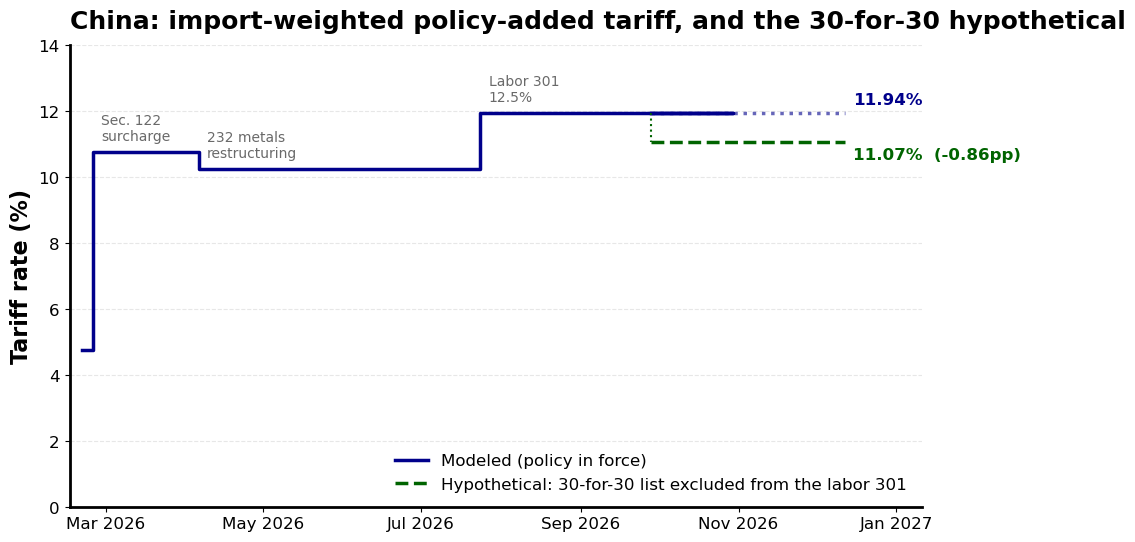

In [6]:
# Figure 1 — China's policy-added rate since the IEEPA revocation, with the hypothetical step.
ch = panel[panel["country_name"] == "CHINA"].copy()
ch["date"] = pd.to_datetime(ch["date"])
ch = ch[ch["date"] >= "2026-02-20"].sort_values("date")
x = list(ch["date"]) + [EVAL_DATE]
y = list(ch["effective tariff"]) + [ch["effective tariff"].iloc[-1]]
x_end = EVAL_DATE + pd.Timedelta(days=75)

fig, ax = plt.subplots(figsize=(11, 6))
ax.step(x, y, where="post", color=PALETTE["primary"], lw=2.5, label="Modeled (policy in force)")
ax.plot([EVAL_DATE, x_end], [china_scen, china_scen], color=PALETTE["tertiary"], lw=2.5,
        ls="--", label="Hypothetical: 30-for-30 list excluded from the labor 301")
ax.plot([EVAL_DATE, EVAL_DATE], [china_base, china_scen], color=PALETTE["tertiary"], lw=1.5, ls=":")
ax.plot([EVAL_DATE, x_end], [china_base, china_base], color=PALETTE["primary"], lw=2.5, ls=":", alpha=0.6)

ax.annotate(f"{china_base:.2f}%", (x_end, china_base), xytext=(6, 4), textcoords="offset points",
            fontsize=12, fontweight="bold", color=PALETTE["primary"], va="bottom")
ax.annotate(f"{china_scen:.2f}%  ({china_scen-china_base:+.2f}pp)", (x_end, china_scen),
            xytext=(6, -4), textcoords="offset points", fontsize=12, fontweight="bold",
            color=PALETTE["tertiary"], va="top")
for d, lab in [("2026-02-24", "Sec. 122\nsurcharge"), ("2026-04-06", "232 metals\nrestructuring"),
               ("2026-07-24", "Labor 301\n12.5%")]:
    v = ch.loc[ch["date"] == d, "effective tariff"].iloc[0]
    ax.annotate(lab, (pd.Timestamp(d), v), xytext=(6, 6), textcoords="offset points",
                fontsize=10, color=PALETTE["neutral"], va="bottom")

ax.set_ylim(0, 14)
ax.set_xlim(pd.Timestamp("2026-02-15"), x_end + pd.Timedelta(days=30))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Tariff rate (%)")
ax.set_title("China: import-weighted policy-added tariff, and the 30-for-30 hypothetical",
             loc="left", pad=12)
ax.grid(axis="y")
ax.legend(loc="lower right")
fig.savefig(figfile + "china-30for30-china-path.png", dpi=150)
plt.show()

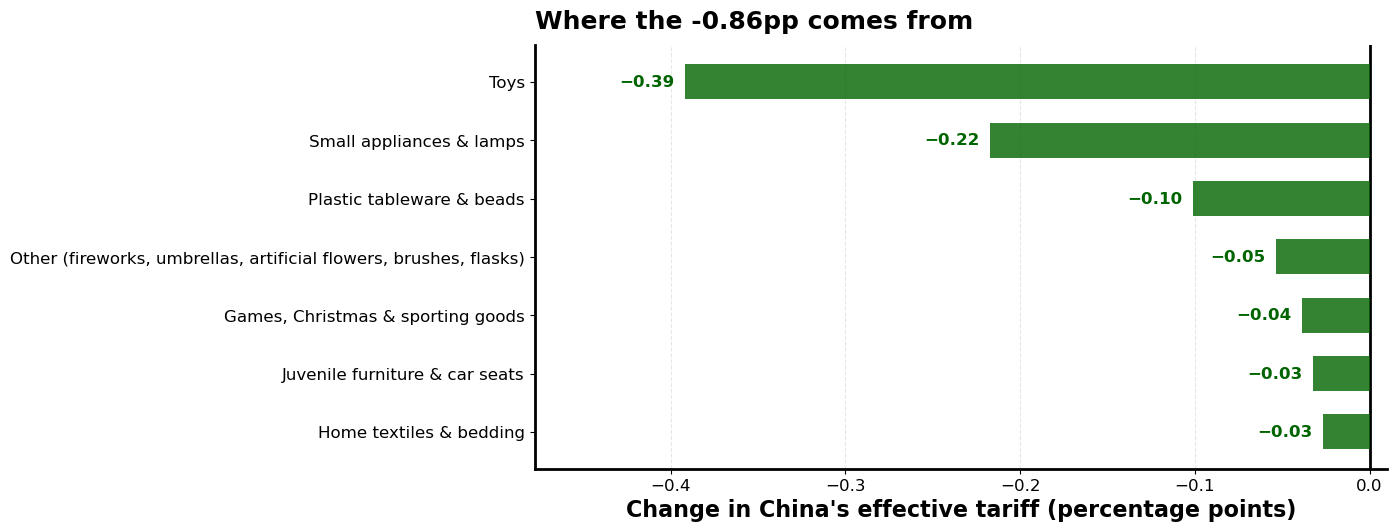

In [7]:
# Figure 2 — where the China step comes from, by product group (pp of China's rate).
contrib = (12.5 * china.loc[changed].groupby("group")["share"].sum()).sort_values()
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(contrib.index, -contrib.values, height=0.6, color=PALETTE["tertiary"],
               alpha=0.8, zorder=3)
for b, v in zip(bars, contrib.values):
    ax.text(-v - 0.006, b.get_y() + b.get_height() / 2, f"−{v:.2f}",
            ha="right", va="center", fontsize=12, fontweight="bold", color=PALETTE["tertiary"])
ax.axvline(0, color="black", lw=2)
ax.set_xlim(-contrib.max() * 1.22, 0.01)
ax.set_xlabel("Change in China's effective tariff (percentage points)")
ax.set_title(f"Where the {china_scen-china_base:+.2f}pp comes from", loc="left", pad=12)
ax.grid(axis="x")
ax.tick_params(axis="y", labelsize=12)
fig.savefig(figfile + "china-30for30-decomposition.png", dpi=150)
plt.show()

## Section 3 — What "2024 levels" means for the list

Exclusion from the labor duty does not make the list duty-free: it returns each line
to its MFN rate plus whatever legacy 2018-19 Section 301 duty it still carries. That
legacy layer is inferred here per HTS10 line as the 2024 collected rate less the
statutory column-1 MFN (`mfn-per-code.csv`), floored at zero. It is small — toys,
the bulk of the list, were on List 4B and never dutied — and it lives in the 2024
baseline, not in the tracker's policy-added rate, so a companion modification of the
legacy lists would only show up as the further step reported below.

In [8]:
L = china[in_list].copy()
L["ave_2024"] = 100 * L["duty"] / L["imports"]
L["mfn"] = L["HS10"].map(MFN_BY_HS10).fillna(0.0)
L["legacy_301"] = (L["ave_2024"] - L["mfn"]).clip(lower=0)
wts = L["imports"] / L["imports"].sum()
mfn_avg, legacy_avg, ave_avg = (L["mfn"] * wts).sum(), (L["legacy_301"] * wts).sum(), (L["ave_2024"] * wts).sum()
legacy_pp = (L["legacy_301"] * L["share"]).sum()   # further China step if legacy lists were also cut

by_group = (L.assign(w=L["imports"]).groupby("group")
            .apply(lambda g: pd.Series({
                "imports ($B)": g["imports"].sum() / 1e9,
                "MFN (%)": np.average(g["mfn"], weights=g["imports"]),
                "legacy 301 (%)": np.average(g["legacy_301"], weights=g["imports"]),
                "2024 collected (%)": np.average(g["ave_2024"], weights=g["imports"]),
            }), include_groups=False)
            .sort_values("imports ($B)", ascending=False))
print(f"List-weighted 2024 collected rate {ave_avg:.2f}% = MFN {mfn_avg:.2f}% + legacy 301 {legacy_avg:.2f}%.")
print(f"Lines carrying a legacy 301 duty (>3pp): ${L.loc[L['legacy_301'] > 3, 'imports'].sum()/1e9:.2f}B "
      f"of ${L['imports'].sum()/1e9:.2f}B.")
print(f"If the legacy lists were ALSO modified for these goods: a further {-legacy_pp:.3f}pp on China "
      f"(the tracker would need a below-baseline adjustment to show it).")
by_group.round(2)

List-weighted 2024 collected rate 2.61% = MFN 1.98% + legacy 301 0.63%.
Lines carrying a legacy 301 duty (>3pp): $2.68B of $29.62B.
If the legacy lists were ALSO modified for these goods: a further -0.044pp on China (the tracker would need a below-baseline adjustment to show it).


,imports ($B),MFN (%),legacy 301 (%),2024 collected (%)
group,,,,
Toys,13.45,0.00,0.00,0.00
Small appliances & lamps,7.47,3.45,0.65,4.10
Plastic tableware & beads,3.48,3.76,0.82,4.58
"Other (fireworks, umbrellas, artificial flowers, brushes, flasks)",1.85,6.71,0.20,6.90
"Games, Christmas & sporting goods",1.34,0.61,4.58,5.18
Juvenile furniture & car seats,1.12,0.00,0.00,0.00
Home textiles & bedding,0.92,7.01,4.94,11.95


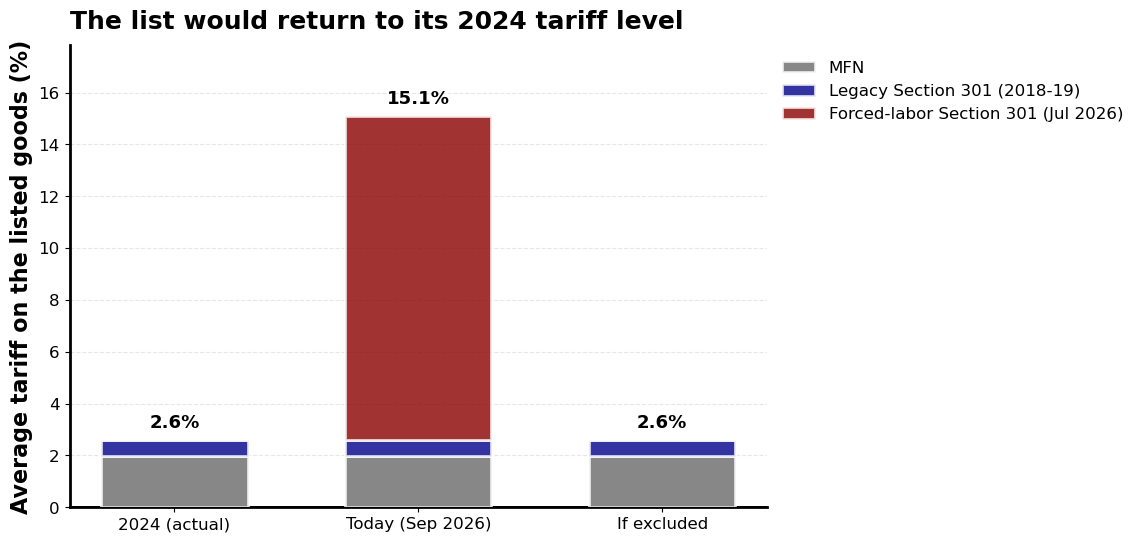

In [9]:
# Figure 3 — average tariff on the listed goods: 2024, today, and if excluded (stacked by layer).
labels = ["2024 (actual)", "Today (Sep 2026)", "If excluded"]
layers = {
    "MFN":                      [mfn_avg,    mfn_avg,    mfn_avg],
    "Legacy Section 301 (2018-19)": [legacy_avg, legacy_avg, legacy_avg],
    "Forced-labor Section 301 (Jul 2026)": [0.0, list_base, list_scen],
}
colors = {"MFN": PALETTE["neutral"], "Legacy Section 301 (2018-19)": PALETTE["primary"],
          "Forced-labor Section 301 (Jul 2026)": PALETTE["secondary"]}
fig, ax = plt.subplots(figsize=(9, 6))
bottom = np.zeros(3)
for name, vals in layers.items():
    ax.bar(labels, vals, bottom=bottom, width=0.6, color=colors[name], alpha=0.8,
           zorder=3, label=name, edgecolor="white", linewidth=2)
    bottom += np.array(vals)
for i, t in enumerate(bottom):
    ax.text(i, t + 0.3, f"{t:.1f}%", ha="center", va="bottom", fontsize=13, fontweight="bold")
ax.axhline(0, color="black", lw=2)
ax.set_ylabel("Average tariff on the listed goods (%)")
ax.set_title("The list would return to its 2024 tariff level", loc="left", pad=12)
ax.set_ylim(0, bottom.max() * 1.18)
ax.grid(axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(figfile + "china-30for30-list-tariff.png", dpi=150)
plt.show()

## Summary

- **The list is ~$29.6B of 2024 U.S. imports from China (6.9% of the total), 124
  HTS10 lines.** Toys are $13.5B of it; games, Christmas and sporting goods, small
  appliances, home textiles and juvenile furniture make up most of the rest.
- **Every listed line carries exactly one modeled duty today, the 12.5% forced-labor
  Section 301.** None is a modeled Section 232 good or a labor Part A exemption, so
  an exclusion takes each line from 12.5 to 0 policy-added tariff.
- **China's import-weighted rate: 11.94% → 11.07%, a step of −0.86pp** (2024 weights).
  Toys alone are −0.39pp of it. The national import-weighted average moves **−0.12pp**
  (11.46% → 11.34%; −0.115pp unrounded).
- **"2024 levels" is not duty-free, but close to it.** The listed goods return to their
  2024 collected rate of ~2.6% — ~2.0% MFN plus ~0.6% legacy Section 301. The legacy
  layer sits in ~$2.7B of home textiles, Christmas/sporting goods and small appliances;
  toys and the juvenile-furniture lines carried no duty at all in 2024. A companion
  modification of the legacy lists would be worth only a further ~−0.04pp on China, and
  the tracker would need a below-baseline adjustment to show it.
- **Caveats.** This is a hypothetical: no instrument, rate or date exists. A partial
  reduction scales linearly (12.5% → 5% is 60% of the step). The toys ex-out (items
  "enabled with radio frequency, Wi-Fi, Ethernet, or Bluetooth" stay dutiable) is not
  resolvable at HTS10, so the toys contribution is a slight overstatement. Hong Kong is
  not covered.